# El panel y la etiqueta: qué es un «inicio» y cuántos hay

El informe no predice si habrá muchos o pocos casos: predice el **inicio** de
un brote, que es distinto de su continuación. Este cuaderno describe el panel
publicado y caracteriza esa etiqueta, que es la que decide todo lo demás.

**Qué necesita.** Solo `datos/panel/` y el entorno del proyecto
(`uv sync --locked --project pipeline`). No usa predicciones ni modelos.

**Cuánto tarda.** Menos de un minuto.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "pipeline" / "src"))
sys.path.insert(0, str(RAIZ / "pipeline" / "tools"))

from exportar_entregable import leer_panel  # noqa: E402
from sat_dengue_pipeline.evaluation import validacion_anual as va  # noqa: E402

PANEL = RAIZ / "datos" / "panel"

panel, esquema = leer_panel(PANEL)
print(f"{len(panel)} filas | {panel.municipality_code.nunique()} municipios "
      f"| {panel.year_month.min()} a {panel.year_month.max()}")

16416 filas | 76 municipios | 2007-01 a 2024-12


## 1. Qué hay en el panel

Cada fila es un municipio en un mes. Las columnas se agrupan por rol: claves,
metadatos, predictores (los que el modelo puede ver al cierre del mes de
origen), objetivos y controles.

In [2]:
roles = esquema["column_roles"]
pd.DataFrame(
    [{"rol": rol, "columnas": len(nombres), "ejemplos": ", ".join(nombres[:4])}
     for rol, nombres in roles.items()]
)

,rol,columnas,ejemplos
0,key,2,"municipality_code, year_month"
1,metadata,2,"department_code, municipality_name"
2,feature,33,"dengue_notifications_count, dengue_grave_notif..."
3,target,0,
4,control,15,"in_epi_coverage, epi_count_status, expected_da..."


El canal endémico necesita cinco años previos del mismo mes calendario, así
que las columnas que dependen de él están vacías al principio de la serie.
Esto no es un defecto de los datos: es la razón por la que la evaluación
empieza en 2012 y no en 2007.

In [3]:
cobertura = (
    panel.assign(anio=panel.year_month.str[:4])
    .groupby("anio")
    .agg(filas=("municipality_code", "size"),
         con_canal=("p75_canal_t", lambda s: int(s.notna().sum())),
         casos=("dengue_notifications_count", "sum"))
)
cobertura.head(8)

,filas,con_canal,casos
anio,,,
2007,912,0,4206
2008,912,0,2977
2009,912,0,5697
2010,912,0,15562
2011,912,0,4759
2012,912,912,10774
2013,912,912,20213
2014,912,912,14835


## 2. La etiqueta: inicio contra continuación

Un mes está **en exceso** cuando sus casos superan el percentil 75 del mismo
mes calendario en los cinco años anteriores del propio municipio. Un **inicio**
es el primer mes en exceso después de uno que no lo estaba. Todo lo demás que
está en exceso es continuación.

La distinción importa porque un episodio de exceso dura varios meses: un modelo
puede sacar buenas métricas agregadas limitándose a reconocer brotes que ya
están en curso, que son justamente los que la autoridad sanitaria ya conoce.

In [4]:
historia = {h: va.historia_desde_panel(panel, h) for h in (1, 2)}
resumen = pd.DataFrame(
    [
        {
            "horizonte": f"T+{h}",
            "filas con etiqueta": len(d),
            "meses en exceso (objetivo)": int(((d.inicio == 1) | (d.exceso_t == 1)).sum()),
            "inicios": int((d.inicio == 1).sum()),
            "cohorte evaluable (fuera de exceso en el origen)": int((d.exceso_t == 0).sum()),
            "inicios en esa cohorte": int(((d.inicio == 1) & (d.exceso_t == 0)).sum()),
        }
        for h, d in historia.items()
    ]
)
resumen

,horizonte,filas con etiqueta,meses en exceso (objetivo),inicios,cohorte evaluable (fuera de exceso en el origen),inicios en esa cohorte
0,T+1,11780,5296,1266,7750,1266
1,T+2,11704,4865,1261,7711,872


La **cohorte evaluable** son los municipios que no están en exceso en el mes de
origen, que es donde un inicio es posible. Es sobre esas filas, y no sobre todo
el panel, que se mide la sensibilidad del informe.

In [5]:
inicios_anio = pd.concat(
    [
        d[(d.exceso_t == 0) & d.anio_objetivo.between(2018, 2024)]
        .groupby("anio_objetivo")
        .inicio.sum()
        .rename(f"T+{h}")
        for h, d in historia.items()
    ],
    axis=1,
)
inicios_anio.loc["total"] = inicios_anio.sum()
inicios_anio

,T+1,T+2
anio_objetivo,,
2018,91,65
2019,118,82
2020,69,53
2021,52,49
2022,89,67
2023,125,81
2024,103,67
total,647,464


### Por qué estas cifras no son las del artículo, y está bien

El informe reporta **641 inicios en T+1 y 459 en T+2** para 2018-2024, y aquí
salen unos pocos más. No es una discrepancia: son dos cohortes distintas.

- Lo de arriba es **todo lo que el panel admite**: cada fila municipio-mes cuya
  etiqueta es observable y que no está en exceso en el origen.
- El artículo mide sobre el **conjunto común del arnés**: las filas que todas
  las configuraciones comparadas tienen completas, para que la diferencia entre
  dos recetas sea atribuible a la receta y no a que una vio más filas. Ese
  filtro deja fuera unas pocas filas con predictores incompletos, y con ellas
  algunos inicios.

La escalera completa, que es lo que conviene tener claro antes de leer
cualquier porcentaje:

In [6]:
escalera = pd.DataFrame(
    [
        {
            "cohorte": "panel completo, todos los años",
            "T+1": int((historia[1].exceso_t == 0).sum()),
            "T+2": int((historia[2].exceso_t == 0).sum()),
        },
        {
            "cohorte": "inicios, todos los años",
            "T+1": int(((historia[1].inicio == 1) & (historia[1].exceso_t == 0)).sum()),
            "T+2": int(((historia[2].inicio == 1) & (historia[2].exceso_t == 0)).sum()),
        },
        {
            "cohorte": "inicios, 2018-2024",
            "T+1": int(inicios_anio.loc["total", "T+1"]),
            "T+2": int(inicios_anio.loc["total", "T+2"]),
        },
        {"cohorte": "inicios evaluados en el artículo", "T+1": 641, "T+2": 459},
    ]
).set_index("cohorte")
escalera

,T+1,T+2
cohorte,,
"panel completo, todos los años",7750,7711
"inicios, todos los años",1266,872
"inicios, 2018-2024",647,464
inicios evaluados en el artículo,641,459


Un detalle que vale la pena notar en la tabla anterior: en T+1 todo inicio está,
por construcción, fuera de exceso en el origen —el mes anterior al objetivo *es*
el origen—, así que las dos primeras filas coinciden. En T+2 no, porque el mes
anterior al objetivo es T+1 y el municipio puede haber entrado en exceso ahí.

## 3. De dónde arrancan los inicios

Esta es la pregunta que más dice sobre el techo del problema: cuántos inicios
empiezan en un municipio que **no notificó ningún caso** en el mes de origen.
Ahí un sistema basado en conteos no tiene señal que ordenar, porque la entrada
es cero para todos los candidatos.

In [7]:
arranque = []
for h, d in historia.items():
    cohorte = d[(d.exceso_t == 0) & d.anio_objetivo.between(2018, 2024)]
    inicios = cohorte[cohorte.inicio == 1]
    arranque.append(
        {
            "horizonte": f"T+{h}",
            "inicios": len(inicios),
            "desde cero casos": int((inicios.casos_t == 0).sum()),
            "%": round(100 * (inicios.casos_t == 0).mean(), 1),
            "mediana de casos en el origen": float(inicios.casos_t.median()),
        }
    )
pd.DataFrame(arranque)

,horizonte,inicios,desde cero casos,%,mediana de casos en el origen
0,T+1,647,186,28.7,2.0
1,T+2,464,156,33.6,2.0


## 4. Estacionalidad

Los inicios no se reparten parejo en el año. El modelo recibe el mes del año
como predictor, así que parte de lo que aprende es esta forma.

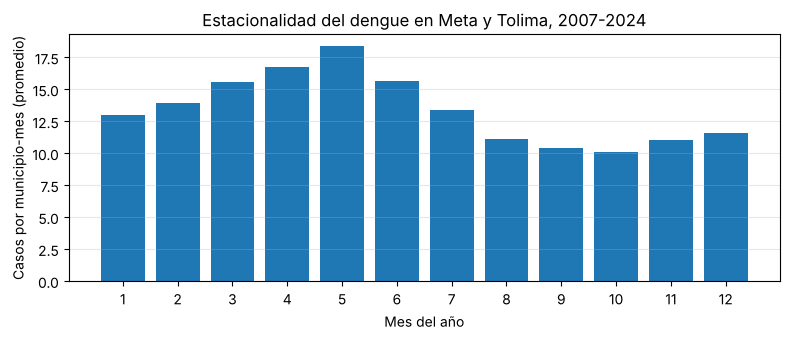

In [8]:
mes = panel.loc[:, ["municipality_code", "year_month", "dengue_notifications_count"]].copy()
mes["mes"] = mes.year_month.str[5:].astype(int)
por_mes = mes.groupby("mes").dengue_notifications_count.mean()

figura, eje = plt.subplots(figsize=(8, 3.5))
eje.bar(por_mes.index, por_mes.values)
eje.set_xticks(range(1, 13))
eje.set_xlabel("Mes del año")
eje.set_ylabel("Casos por municipio-mes (promedio)")
eje.set_title("Estacionalidad del dengue en Meta y Tolima, 2007-2024")
eje.grid(alpha=0.3, axis="y")
figura.tight_layout()
plt.show()

## 5. Qué tan desigual es la carga entre municipios

In [9]:
por_municipio = (
    panel.groupby("municipality_code")
    .dengue_notifications_count.sum()
    .sort_values(ascending=False)
)
acumulado = por_municipio.cumsum() / por_municipio.sum()
print(f"{len(por_municipio)} municipios, {int(por_municipio.sum())} casos en total")
print(f"Los 10 municipios con más casos concentran el {100 * acumulado.iloc[9]:.1f} %")
print(f"La mitad de los casos está en los primeros {int((acumulado < 0.5).sum()) + 1} municipios")
por_municipio.head(10).to_frame("casos")

76 municipios, 220277 casos en total
Los 10 municipios con más casos concentran el 70.3 %
La mitad de los casos está en los primeros 3 municipios


,casos
municipality_code,
73001,55109
50001,45582
50006,11815
73268,11781
50313,6615
73449,5471
73168,5356
73411,4628
73443,4256


## Lectura

Tres cosas que condicionan todo lo que viene después:

1. La cohorte evaluable es bastante más chica que el panel, porque solo cuentan
   los municipios fuera de exceso en el mes de origen, y el conjunto común del
   arnés la recorta un poco más. Las métricas del informe se leen sobre esas
   filas y no sobre el panel entero.
2. Cerca de un tercio de los inicios arranca **sin un solo caso notificado** en
   el municipio durante el mes de origen. Ahí ningún método basado en conteos
   tiene nada que ordenar: la entrada es cero para todos los candidatos. Ese es
   un techo que no se mueve con un modelo mejor, sino con información nueva.
3. La carga está extremadamente concentrada: la mitad de los casos de dieciocho
   años está en tres municipios. Eso explica por qué el presupuesto de alertas
   se reparte globalmente entre los dos departamentos y no por cupos fijos, y
   por qué una regla de reparto por departamento no mejoró el resultado.